<a href="https://colab.research.google.com/github/ProfeAgudelo/Modelaci-n_Estocastica/blob/main/Problema_1_Confiabilidad_de_sistema_multicomponente_con_C%C3%B3pula_Gaussiana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Problema #1 : Confiabilidad de sistema Multicomponente con Cópula Gaussiana
**Presentado por**: Dayron Javier Agudelo\
**Fecha**: 19 de noviembre de 2026\
**Fundación Universitaria Los Libertadores**

En primer lugar, se realiza la configuración del entorno. Para ello se importan las librerias y se configuran los colores para la visualización

In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, expon, uniform, spearmanr, t

In [147]:
# =================================
# Colores para la visualización
# =================================

colores = {
    # Colores institucionales
    "principal": "#004F4A",
    "secundario": "#267C72",
    "terciario": "#76A99C",
    "claro": "#B8D0C7",
    # Colores complementarios
    "dorado": "#D69B48",
    "terracota": "#C76B5A",
    "azul": "#557A9C",
    "gris_azulado": "#647078",
    # Colores estructurales
    "fondo": "#F3F5F3",
    "blanco": "#FFFFFF",
    "texto": "#263238",
    "cuadricula": "#DDE3DF"
}

## Análisis exploratorio de los datos

In [148]:
data = pd.read_csv('/content/drive/MyDrive/Especialización en matemática aplicada/Modelación estocastica/Problema #1/datos_confiabilidad.csv')

In [149]:
data.head()

,ruido_sensor_1,ruido_sensor_2,ruido_sensor_3,ruido_sensor_4,ruido_sensor_5,tiempo_respuesta_1,tiempo_respuesta_2,tiempo_respuesta_3,tiempo_respuesta_4,tiempo_respuesta_5,error_medicion_1,error_medicion_2,error_medicion_3,error_medicion_4,error_medicion_5,temperatura,vibracion,voltaje,falla_sistema
0,2.502071,2.541307,0.914305,0.882714,2.103349,2.599360,0.490576,1.188897,3.227320,1.374766,-1.104881,-1.005745,1.831273,0.992859,-0.041964,24.820997,0.163567,12.125708,0
1,1.740494,-1.588195,-1.755260,-0.205856,0.088280,2.135727,0.021783,2.396443,0.679711,1.169203,-1.452959,-1.757090,1.784844,1.923084,0.924102,29.844016,0.176282,10.775090,0
2,1.580329,2.845928,-0.986591,-0.198471,1.851627,0.842062,1.356226,6.665887,1.121299,2.260488,-1.448042,-1.969767,-1.510877,-1.000308,1.767436,34.246277,0.092609,11.833183,0
3,1.292723,0.458160,0.074732,1.403383,0.048913,4.718138,2.109203,1.384531,0.310385,5.734003,0.361607,0.916166,0.478468,0.893282,-1.992262,35.036534,0.632798,12.037283,0
4,0.312343,1.727684,-1.532473,-2.202358,0.300033,0.884468,2.702262,1.476109,0.241005,1.986098,-0.822494,-0.767286,-0.451649,0.742006,-0.248693,25.073347,0.302833,12.476454,0


In [150]:
ruido_cols = [f'ruido_sensor_{i}' for i in range(1, 6)]
data_ruido = data[ruido_cols]
tiempo_cols = [f'tiempo_respuesta_{i}' for i in range(1, 6)]
data_tiempo = data[tiempo_cols]
error_cols = [f'error_medicion_{i}' for i in range(1, 6)]
data_error = data[error_cols]

In [151]:
#Descripción del ruido
data_ruido.describe().drop('std')

,ruido_sensor_1,ruido_sensor_2,ruido_sensor_3,ruido_sensor_4,ruido_sensor_5
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.002997,0.031786,0.000306,-0.002187,0.026622
min,-4.529790,-5.329520,-4.428018,-5.585675,-5.713272
25%,-0.988309,-1.014986,-0.990422,-1.044955,-1.025644
50%,-0.007638,0.036654,0.033592,0.005561,0.056477
75%,1.053862,1.042676,0.997754,1.026299,1.041367
max,6.603212,4.918354,4.278804,4.860818,5.716971


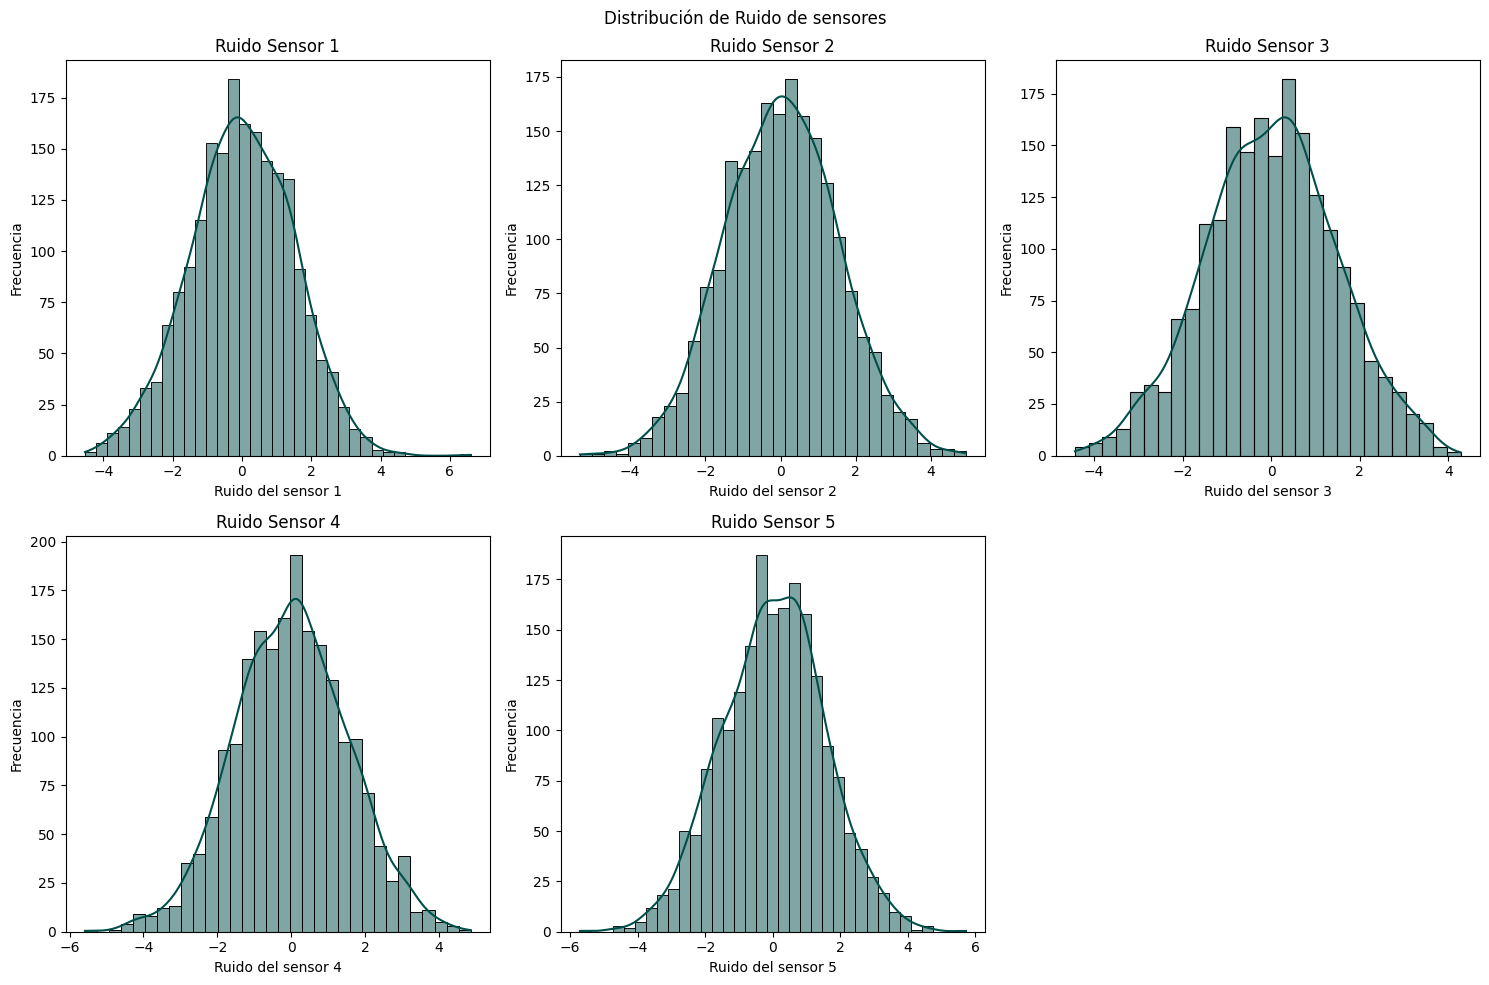

In [152]:
#Grafico de las distribuciones para el ruido
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
ax = ax.flatten()

for i in range(len(ruido_cols)):
    sns.histplot(data = data_ruido[ruido_cols[i]], kde=True, color=colores['principal'], ax=ax[i])
    ax[i].set_xlabel(f'Ruido del sensor {i + 1}')
    ax[i].set_ylabel('Frecuencia')
    ax[i].set_title(f'Ruido Sensor {i + 1}')
    ax[5].axis('off')
fig.suptitle('Distribución de Ruido de sensores')
plt.tight_layout()
plt.show()

In [153]:
#Descripción del tiempo de respuesta
data_tiempo.describe().drop('std')

,tiempo_respuesta_1,tiempo_respuesta_2,tiempo_respuesta_3,tiempo_respuesta_4,tiempo_respuesta_5
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1.964010,1.979044,2.000795,2.024658,1.991060
min,0.001556,0.000686,0.003732,0.002632,0.000355
25%,0.558832,0.566522,0.594846,0.569670,0.565471
50%,1.375564,1.340652,1.371975,1.389121,1.400753
75%,2.733998,2.730240,2.727649,2.758188,2.813060
max,17.025002,14.596700,13.774662,16.338255,11.480702


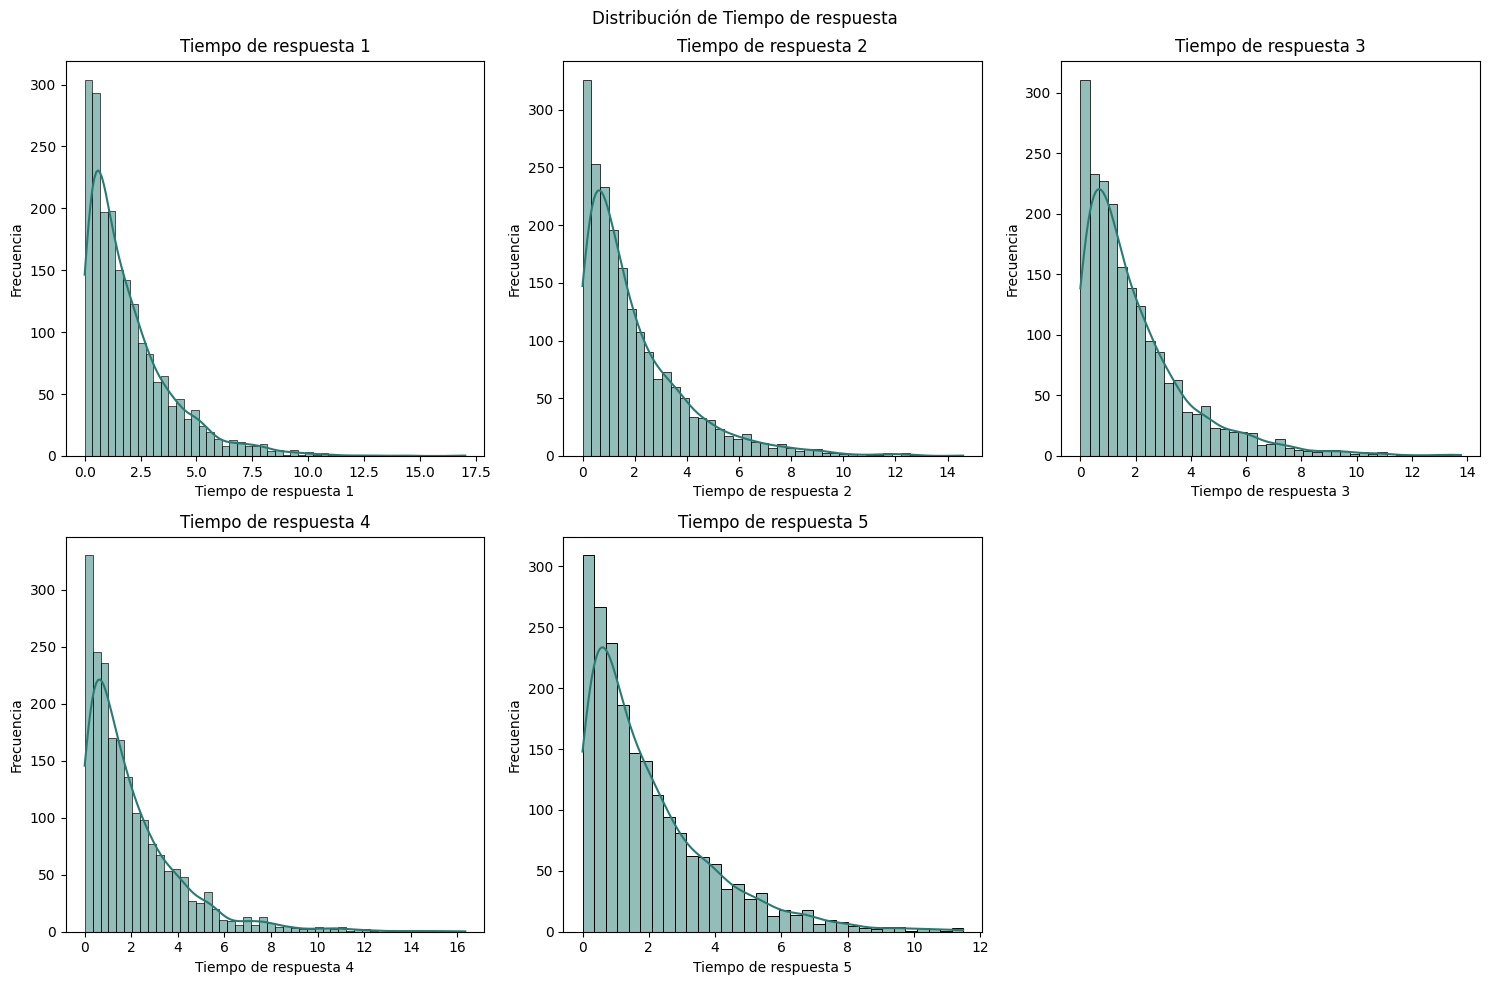

In [154]:
#Grafico de las distribuciones para el tiempo de respuesta
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
ax = ax.flatten()

for i in range(len(tiempo_cols)):
    sns.histplot(data = data_tiempo[tiempo_cols[i]], kde=True, color=colores['secundario'], ax=ax[i])
    ax[i].set_xlabel(f'Tiempo de respuesta {i + 1}')
    ax[i].set_ylabel('Frecuencia')
    ax[i].set_title(f'Tiempo de respuesta {i + 1}')
    ax[5].axis('off')
fig.suptitle('Distribución de Tiempo de respuesta')
plt.tight_layout()
plt.show()

In [155]:
#Descripción de los errores en la medición
data_error.describe().drop('std')

,error_medicion_1,error_medicion_2,error_medicion_3,error_medicion_4,error_medicion_5
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,-0.036497,0.000468,-0.013901,-0.016665,-0.000228
min,-1.999525,-1.999468,-1.999054,-1.998796,-1.998040
25%,-1.057028,-0.996687,-1.036451,-1.008212,-1.046338
50%,-0.021337,-0.014876,-0.008292,-0.017760,0.002460
75%,0.940386,1.036427,0.985601,0.943875,1.054371
max,1.997287,1.998315,1.995972,1.999124,1.996076


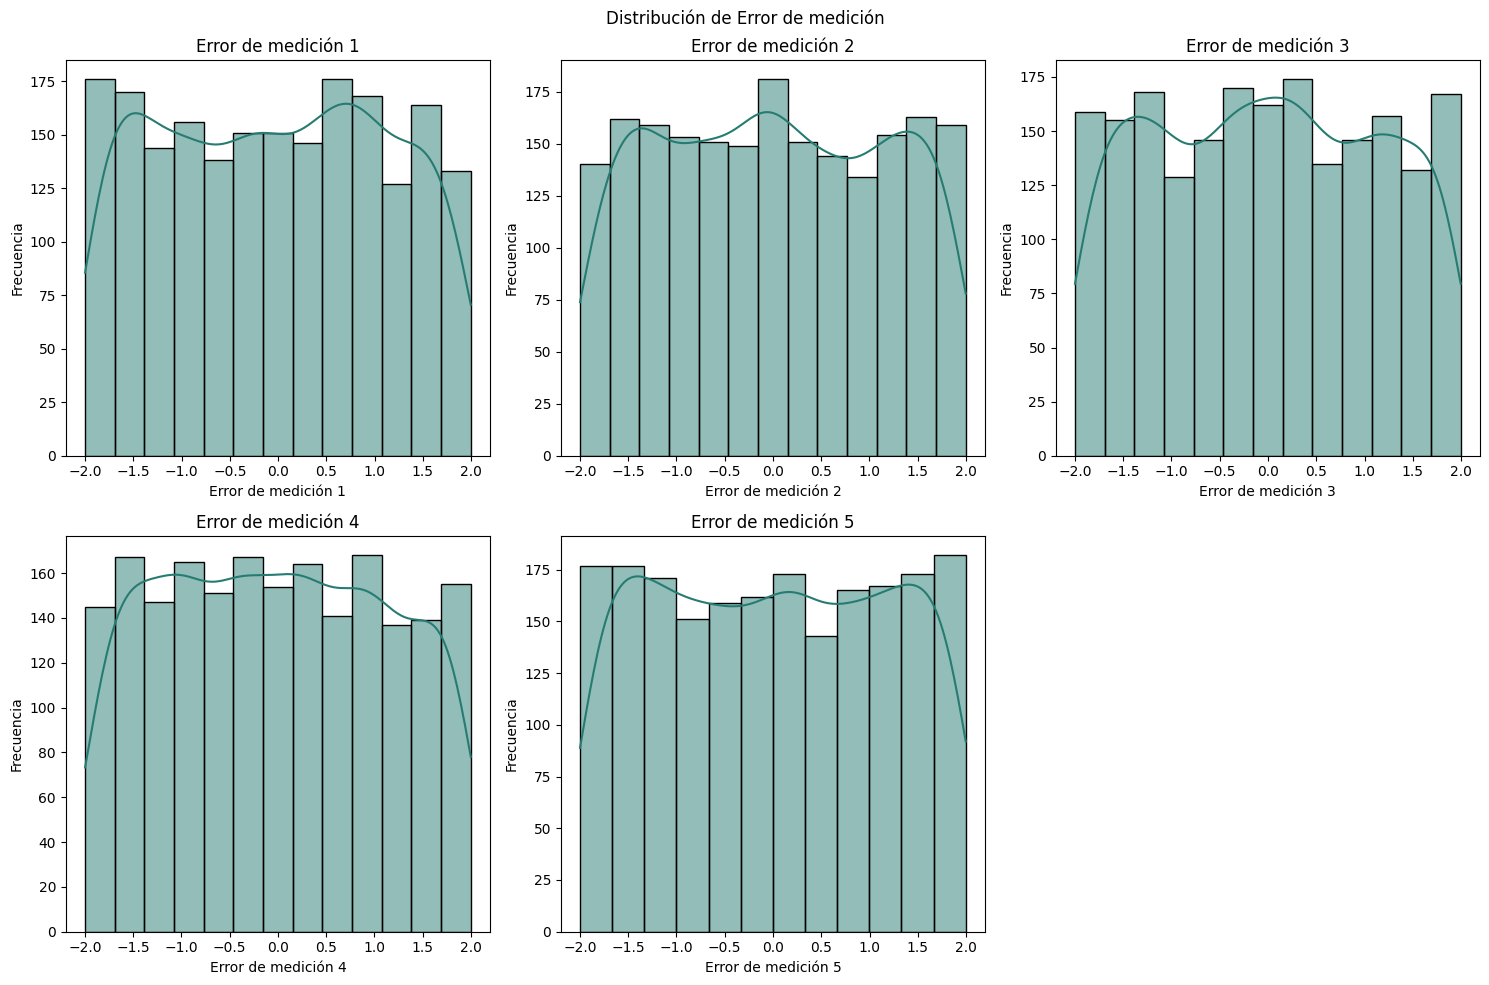

In [156]:
#Grafico de las distribuciones para el error
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
ax = ax.flatten()

for i in range(len(error_cols)):
    sns.histplot(data = data_error[error_cols[i]], kde=True, color=colores['secundario'], ax=ax[i])
    ax[i].set_xlabel(f'Error de medición {i + 1}')
    ax[i].set_ylabel('Frecuencia')
    ax[i].set_title(f'Error de medición {i + 1}')
    ax[5].axis('off')
fig.suptitle('Distribución de Error de medición')
plt.tight_layout()
plt.show()

In [157]:
data['vibracion'].describe().drop('std')

,vibracion
count,2000.000000
mean,0.509322
min,0.000175
25%,0.139497
50%,0.338888
75%,0.708172
max,5.876806


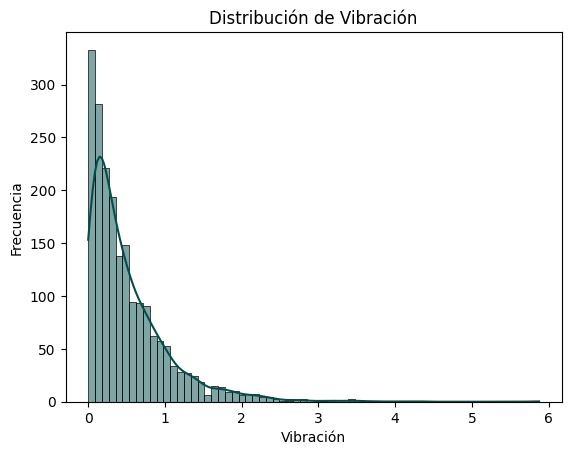

In [158]:
sns.histplot(data = data['vibracion'], kde=True, color=colores['principal'])
plt.xlabel('Vibración')
plt.ylabel('Frecuencia')
plt.title('Distribución de Vibración')
plt.show()

##Cálculo de los estimadores

In [159]:
for i in range(len(ruido_cols)):
    print(f'Ruido Sensor {i + 1}')
    print(f'Desviación estándar muestral: {round(data_ruido[ruido_cols[i]].std(ddof=1),5)}')

Ruido Sensor 1
Desviación estándar muestral: 1.48756
Ruido Sensor 2
Desviación estándar muestral: 1.4954
Ruido Sensor 3
Desviación estándar muestral: 1.48143
Ruido Sensor 4
Desviación estándar muestral: 1.53095
Ruido Sensor 5
Desviación estándar muestral: 1.52096


In [160]:
for i in range(len(tiempo_cols)):
    print(f'tiempo de respuesta {i + 1}')
    print(f'Valor de Lamda para el tiempo {i + 1}: {round(1/(data_tiempo[tiempo_cols[i]].mean()),)}')

tiempo de respuesta 1
Valor de Lamda para el tiempo 1: 1
tiempo de respuesta 2
Valor de Lamda para el tiempo 2: 1
tiempo de respuesta 3
Valor de Lamda para el tiempo 3: 0
tiempo de respuesta 4
Valor de Lamda para el tiempo 4: 0
tiempo de respuesta 5
Valor de Lamda para el tiempo 5: 1


In [161]:
for i in range(len(error_cols)):
    print(f'Error en la medición {i + 1}')
    print(f'Valores extremos para el error {i + 1}: Valor de a = {round(data_error[error_cols[i]].min(),5)} y valor de b = {round(data_error[error_cols[i]].max(),5)}')

Error en la medición 1
Valores extremos para el error 1: Valor de a = -1.99953 y valor de b = 1.99729
Error en la medición 2
Valores extremos para el error 2: Valor de a = -1.99947 y valor de b = 1.99832
Error en la medición 3
Valores extremos para el error 3: Valor de a = -1.99905 y valor de b = 1.99597
Error en la medición 4
Valores extremos para el error 4: Valor de a = -1.9988 y valor de b = 1.99912
Error en la medición 5
Valores extremos para el error 5: Valor de a = -1.99804 y valor de b = 1.99608


In [162]:
#Resumen de los estimadores
sigmas = data_ruido[ruido_cols].std(ddof=1).values
lambdas = 1.0 / data_tiempo[tiempo_cols].mean().values
a_hats = data_error[error_cols].min().values
b_hats = data_error[error_cols].max().values
mean_V = data['vibracion'].mean()

##Cálculo de la correlación de Spearman y prueba de hipotesis

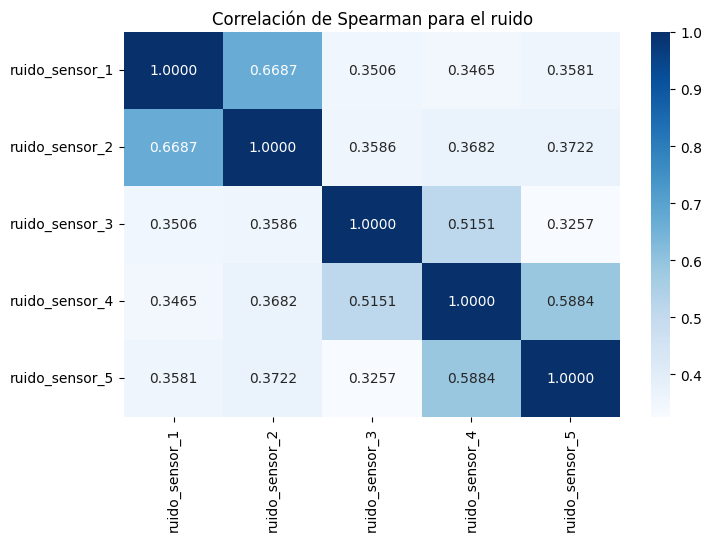

In [163]:
R = spearmanr(data_ruido)
data_R = pd.DataFrame(R[0])

#Grafico de correlación
plt.figure(figsize=(8,5))
cmap = sns.color_palette("Blues", as_cmap=True)
sns.heatmap(data_R, annot=True, cmap= cmap, fmt=".4f",
            xticklabels=data_ruido.columns, yticklabels=data_ruido.columns)
plt.title('Correlación de Spearman para el ruido')
plt.show()

In [164]:
#Definición de la matriz de Cholesky
L_rho = np.linalg.cholesky(R[0])
L_rho

array([[1.        , 0.        , 0.        , 0.        , 0.        ],
       [0.66874267, 0.74349394, 0.        , 0.        , 0.        ],
       [0.35062266, 0.16700749, 0.92150543, 0.        , 0.        ],
       [0.34653712, 0.18356305, 0.39385684, 0.83132029, 0.        ],
       [0.35813351, 0.17850056, 0.18483076, 0.43149134, 0.78710276]])

In [165]:
n = len(data)
data_R_t = data_R.map(lambda x: round(x * np.sqrt((n - 2) / (1 - x**2)), 4) if abs(x) != 1 else np.nan)
data_R_t

,0,1,2,3,4
0,NaN,40.2049,16.7349,16.5131,17.1455
1,40.2049,NaN,17.1736,17.7030,17.9256
2,16.7349,17.1736,NaN,26.8624,15.3982
3,16.5131,17.7030,26.8624,NaN,32.5257
4,17.1455,17.9256,15.3982,32.5257,NaN


In [166]:
data_R_pVal = data_R_t.map(lambda x: 2*t.sf(abs(x), df=n-2))
data_R_pVal

,0,1,2,3,4
0,NaN,1.732578e-259,6.210138e-59,1.602869e-57,1.388652e-61
1,1.732578e-259,NaN,9.108904e-62,2.940837e-65,9.499411e-67
2,6.210138e-59,9.108904e-62,NaN,5.824863e-136,1.211426e-50
3,1.602869e-57,2.940837e-65,5.824863e-136,NaN,1.316461e-186
4,1.388652e-61,9.499411e-67,1.211426e-50,1.316461e-186,NaN


##Estimación empirica de la falla.

In [167]:
prop_data = (data['falla_sistema'].sum())/n
print(f'La proporción de fallas es: {round(prop_data, 5)}')

La proporción de fallas es: 0.0255


In [168]:
IC_prop_data_pos = prop_data + 1.96 * np.sqrt((prop_data * (1 - prop_data)) / n)
IC_prop_data_neg = prop_data - 1.96 * np.sqrt((prop_data * (1 - prop_data)) / n)
print('Con un 95% de confiabilidad es posible afirmar que la proporción se encuentra entre: ')
print(f'[{round(IC_prop_data_neg,5)} , {round(IC_prop_data_pos,5)}]')

Con un 95% de confiabilidad es posible afirmar que la proporción se encuentra entre: 
[0.01859 , 0.03241]


##Modelo de Monte Carlo para fallas del sistema

In [169]:
#Variables proias del sistema
alpha = 0.25
beta_v = 0.10
theta = 5.5

def falla_sistema_sim(n, sigmas, lambdas, a_hats, b_hats, mean_V, K=5, L=L_rho, alpha = alpha, beta_v = beta_v, thetha = theta):
  rng = np.random.default_rng(42)
  X = rng.standard_normal(size=(n, K))
  X_prime = (X @ L.T) * sigmas #Ruido con correlación
  T = rng.exponential(scale=1/lambdas, size=(n,K)) #Tiempo de respuesta
  E = rng.uniform(low=a_hats, high=b_hats, size=(n,K)) #Error Medido
  V = rng.exponential(scale=mean_V, size=(n,1)) #Vibración (Indagar al profe cual es el parámetro correcto de la exponencial)

  #Función de falla
  fn = np.abs(X_prime) + alpha*T + beta_v*V + abs(E) > theta

  #Falla en el sistema
  fn_a = fn[: , 0] & fn[:, 1]
  fn_b = fn[:, 2]
  fn_c = fn[:, 3] & fn[: , 4]

  return (fn_a | fn_b | fn_c).astype(float)

def estimadores_monte_carlo(data):
  prop_sis = data.mean()
  IC_prop_sis_pos = prop_sis + 1.96 * np.sqrt((prop_sis * (1 - prop_sis))/len(data))
  IC_prop_sis_neg = prop_sis - 1.96 * np.sqrt((prop_sis * (1 - prop_sis))/len(data))
  return prop_sis, IC_prop_sis_pos, IC_prop_sis_neg

In [170]:
n = [100,500,1000,5000,10000,50000]
resultados = []

for i in range (len(n)):
  data_monte_carlo = falla_sistema_sim(n[i], sigmas, lambdas, a_hats, b_hats, mean_V)
  prop_sis, IC_prop_sis_pos, IC_prop_sis_neg = estimadores_monte_carlo(data_monte_carlo)
  resultados.append({
        "n": n[i],
        "prop_sis": prop_sis,
        "IC_pos": IC_prop_sis_pos,
        "IC_neg": IC_prop_sis_neg,
    })

resultados_df = pd.DataFrame(resultados)
resultados_df


,n,prop_sis,IC_pos,IC_neg
0,100,0.01000,0.029502,-0.009502
1,500,0.02000,0.032272,0.007728
2,1000,0.02300,0.032291,0.013709
3,5000,0.02280,0.026937,0.018663
4,10000,0.02420,0.027212,0.021188
5,50000,0.02434,0.025691,0.022989


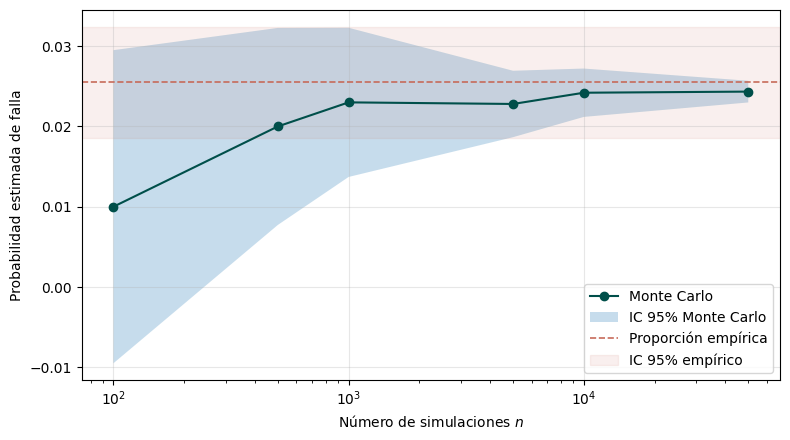

In [171]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(resultados_df["n"], resultados_df["prop_sis"], marker="o", label="Monte Carlo",color= colores['principal'])
ax.fill_between(resultados_df["n"], resultados_df["IC_neg"], resultados_df["IC_pos"],
                alpha=0.25, label="IC 95% Monte Carlo")

# Referencia empírica
ax.axhline(prop_data, color=colores['terracota'], ls="--", lw=1.2, label="Proporción empírica")
ax.axhspan(IC_prop_data_neg, IC_prop_data_pos, color=colores['terracota'], alpha=0.10,
           label="IC 95% empírico")

ax.set_xscale("log")
ax.set_xlabel("Número de simulaciones $n$")
ax.set_ylabel("Probabilidad estimada de falla")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()